# Quantization and QLoRA

The [previous lecture](peft_lora.ipynb) ended with a problem. LoRA removes almost all of the *training* state, but the frozen base weights still have to sit in GPU memory. Qwen2.5-7B needs about 15 GB for its 16-bit weights alone, which fills a 16 GB T4 before training even starts. **Quantization** stores those weights with fewer bits, and **QLoRA** trains LoRA adapters on top of a quantized base.

This lecture is about using these tools well, not about deriving them. The questions are the ones you face in practice: *Will this model fit? What do I lose? Which format should I use for this job? How do I set it up, and what can go wrong?*

**What you will learn**

1. How to estimate the memory a model needs for inference, full fine-tuning, LoRA, and QLoRA.
2. What quantization does to a weight, and why storing a scale per small **block** of weights matters.
3. Which quantization format suits which job: fine-tuning, GPU serving, or running on a laptop.
4. How QLoRA combines a 4-bit frozen base with 16-bit LoRA adapters, and how to set it up with Hugging Face.
5. What to do with the adapter after training, and the common mistakes to avoid.

**Prerequisites:** [Number formats for neural networks](floating_point_formats.ipynb) (fp32, fp16, bf16, and mixed precision) · [PEFT and LoRA](peft_lora.ipynb) (the 16-bytes-per-parameter accounting, LoRA adapters, merging) · [Fine-tuning with the `Trainer`](../fine_tuning/hf_trainer_fine_tuning.ipynb).

**Setup:** Sections 1–6 use PyTorch and matplotlib only and run on a CPU in a few seconds. Section 7 is **optional**: it downloads **Qwen2.5-1.5B-Instruct** (about 3.1 GB, Apache-2.0), needs a GPU (Kaggle **T4**) and internet, and is switched off by default. The [QLoRA lab](../../labs/qlora_dialogsum/qlora_dialogsum_lab.ipynb) applies everything here to a real fine-tuning task.

In [3]:
import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Circle, FancyBboxPatch, Polygon

torch.manual_seed(0)
GB = 1e9                                # decimal gigabytes, as GPU memory is advertised
FROZEN, TRAINABLE, QUANT = "#d5d8dc", "#f5b041", "#aed6f1"
print("PyTorch", torch.__version__)

PyTorch 2.4.0+cu121


## 1. Will it fit? A memory budget

The first question in any real project is whether the model fits on the GPU you have. A good first estimate is

$$\text{memory} \approx \text{number of parameters} \times \text{bytes per parameter} \; + \; \text{activations and overhead}.$$

| Storage format | Bytes per parameter | Used for |
| --- | ---: | --- |
| fp32 | 4 | optimizer state, master weights |
| fp16 / bf16 | 2 | normal inference and LoRA training |
| int8 | 1 | 8-bit quantization |
| 4-bit (NF4, GPTQ, AWQ, …) | about 0.5 | 4-bit quantization |

What has to be stored depends on what you do with the model:

| Job | What is in memory (before activations) |
| --- | --- |
| **Inference** | the weights, plus the key–value (KV) cache, which grows with batch size × sequence length |
| **Full fine-tuning** | 16 bytes per parameter (weights, gradients, fp32 master copy, two Adam moments), as in Lecture 1 |
| **LoRA** | 16-bit frozen weights (2 bytes each) + 16 bytes per **adapter** parameter |
| **QLoRA** | **4-bit** frozen weights + 16 bytes per adapter parameter |

One practical detail changes the numbers. Quantization libraries such as `bitsandbytes` quantize only the **linear layers inside the decoder blocks**. The token embedding table and the output head stay in 16-bit. For small models with large vocabularies this is a big share: in Qwen2.5-1.5B the embedding table is 233M of the 1.54B parameters.

We reuse the Qwen2.5 configurations from Lecture 1 and split the parameters into "quantizable" (decoder linear layers) and "kept in 16-bit" (embeddings, output head, norms, biases).

In [3]:
QWEN = {   # from Qwen/Qwen2.5-*-Instruct config.json on the Hugging Face Hub (same as Lecture 1)
    "Qwen2.5-0.5B": dict(d=896,  layers=24, heads=14, kv_heads=2, ff=4864,  vocab=151936, tied=True),
    "Qwen2.5-1.5B": dict(d=1536, layers=28, heads=12, kv_heads=2, ff=8960,  vocab=151936, tied=True),
    "Qwen2.5-7B":   dict(d=3584, layers=28, heads=28, kv_heads=4, ff=18944, vocab=152064, tied=False),
}
ALL_LINEAR = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")


def linear_shapes(c):
    d, kv = c["d"], c["kv_heads"] * (c["d"] // c["heads"])
    return {"q_proj": (d, d), "k_proj": (d, kv), "v_proj": (d, kv), "o_proj": (d, d),
            "gate_proj": (d, c["ff"]), "up_proj": (d, c["ff"]), "down_proj": (c["ff"], d)}


def param_split(c):
    """(parameters in decoder linear layers, all other parameters)."""
    shapes = linear_shapes(c)
    linear = c["layers"] * sum(i * o for i, o in shapes.values())
    other = c["layers"] * (sum(shapes[m][1] for m in ("q_proj", "k_proj", "v_proj")) + 2 * c["d"])  # biases, norms
    other += c["vocab"] * c["d"] * (1 if c["tied"] else 2) + c["d"]                               # embeddings, head, final norm
    return linear, other


def lora_params(c, r, targets=ALL_LINEAR):
    return c["layers"] * sum(r * (i + o) for m, (i, o) in linear_shapes(c).items() if m in targets)


NF4_BYTES = (4 + 0.127) / 8      # 4-bit codes + double-quantized block scales (QLoRA paper, Section 3)
INT8_BYTES = 1.0                 # ignoring the small per-row scales


def budget(c, r=16):
    """Weights-plus-training-state memory in GB, activations and KV cache excluded."""
    lin, oth = param_split(c)
    n, lora = lin + oth, lora_params(c, r)
    return {
        "infer 16-bit": 2 * n,
        "infer 8-bit": INT8_BYTES * lin + 2 * oth,
        "infer 4-bit": NF4_BYTES * lin + 2 * oth,
        "full FT": 16 * n,
        "LoRA": 2 * n + 16 * lora,
        # prepare_model_for_kbit_training upcasts the non-quantized parameters to fp32 (4 bytes), see Section 4
        "QLoRA": NF4_BYTES * lin + 4 * oth + 16 * lora,
    }


rows = {name: budget(c) for name, c in QWEN.items()}
cols = list(next(iter(rows.values())))
print(f"{'GB':<14}" + "".join(f"{k:>14}" for k in cols))
for name, b in rows.items():
    print(f"{name:<14}" + "".join(f"{v / GB:>14.2f}" for v in b.values()))
for name, c in QWEN.items():
    lin, oth = param_split(c)
    print(f"{name}: {lin / 1e9:.2f}B parameters in decoder linear layers, {oth / 1e9:.2f}B kept in 16-bit ({oth / (lin + oth):.0%})")

GB              infer 16-bit   infer 8-bit   infer 4-bit       full FT          LoRA         QLoRA
Qwen2.5-0.5B            0.99          0.63          0.46          7.90          1.13          0.87
Qwen2.5-1.5B            3.09          1.78          1.14         24.70          3.38          1.91
Qwen2.5-7B             15.23          8.71          5.55        121.85         15.88          8.37
Qwen2.5-0.5B: 0.36B parameters in decoder linear layers, 0.14B kept in 16-bit (28%)
Qwen2.5-1.5B: 1.31B parameters in decoder linear layers, 0.23B kept in 16-bit (15%)
Qwen2.5-7B: 6.53B parameters in decoder linear layers, 1.09B kept in 16-bit (14%)


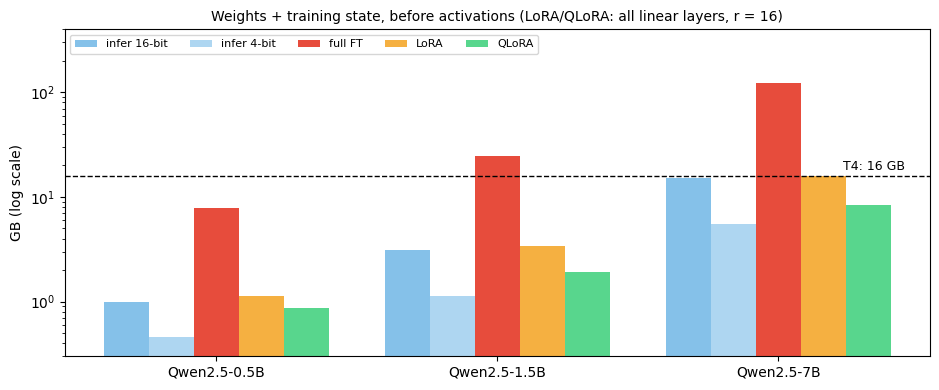

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4))
show = ["infer 16-bit", "infer 4-bit", "full FT", "LoRA", "QLoRA"]
colors = ["#85c1e9", QUANT, "#e74c3c", TRAINABLE, "#58d68d"]
xs = torch.arange(len(QWEN)).float()
w = 0.16
for k, (key, col) in enumerate(zip(show, colors)):
    vals = [rows[n][key] / GB for n in QWEN]
    ax.bar(xs + (k - 2) * w, vals, w, label=key, color=col)
ax.axhline(16, color="k", ls="--", lw=1); ax.text(2.45, 18, "T4: 16 GB", ha="right", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("GB (log scale)"); ax.set_xticks(xs); ax.set_xticklabels(list(QWEN))
ax.set_title("Weights + training state, before activations (LoRA/QLoRA: all linear layers, r = 16)", fontsize=10)
ax.legend(fontsize=8, ncol=5, loc="upper left"); ax.set_ylim(0.3, 400); plt.tight_layout(); plt.show()

**Reading the output**

- **4-bit is not "a quarter of the size".** Qwen2.5-1.5B goes from about 3.1 GB to about 1.1 GB, not 0.8 GB, because 15% of its parameters (mostly the embedding table) stay in 16-bit. You can see the same thing in the real files on the Hub (a *checkpoint* is a saved copy of a model's weights, defined in Section 3): the [GPTQ 4-bit checkpoint](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct-GPTQ-Int4) is 1.15 GB, of which 467 MB is the 16-bit embedding table.
- **QLoRA makes the 7B model trainable on a T4.** LoRA needs about 16 GB before activations, which does not fit. QLoRA needs about 8 GB, which leaves room for activations.
- **Upcasting has a cost.** The QLoRA column assumes the non-quantized parameters are upcast to fp32 for numerical stability, which the standard recipe does (Section 4). For the 7B model, which has a separate output head, those 1.09B parameters take about 4.4 GB in fp32 instead of 2.2 GB in 16-bit.
- **Activations are not in this chart.** They grow with batch size × sequence length, and for long sequences they can exceed the weights. Gradient checkpointing (Section 4) is the usual remedy. With a large vocabulary, the output **logits** are a big extra: one score per vocabulary entry for every token. Section 7 measures this.
- **For inference, the KV cache is extra.** It grows with every generated token and every sequence in the batch, so a model that "fits" can still run out of memory with long prompts or large batches.

> **Practical rule:** estimate first with this arithmetic, then *measure* on the real GPU (`torch.cuda.max_memory_allocated()`), as Section 7 and the lab do.

## 2. What quantization does to a weight

Quantization replaces each 16-bit weight by a 4-bit **code**, which is an index into a short list of allowed values called **levels**. Each block of weights also keeps one shared number, the **scale**, that restores the original size. The process has two parts: *quantization*, done once when the model is loaded, and *dequantization*, done every time a layer runs.

**Quantization (once, at load time)**

1. **Split into blocks.** The weights of a layer are cut into small groups. QLoRA uses blocks of 64 weights; the example below uses 4 to keep the arithmetic visible.
2. **Find the scale of each block.** The scale is the largest absolute weight in the block.
3. **Normalize.** Divide every weight by its block's scale. All weights now lie between −1 and 1, and the largest one is exactly ±1. This puts every block on the same ruler, whatever its size.
4. **Round to the nearest level.** The format provides 16 allowed levels between −1 and 1 (which levels, we see below). Each normalized weight is replaced by the nearest one, and we record only the level's **index**, a 4-bit number from 0 to 15.
5. **Store codes and scale, discard the 16-bit weights.** What stays in memory is one 4-bit code per weight and one scale per block.

**Dequantization (every time the layer runs)**

6. **Look up and rescale.** Each code is turned back into its level, and the level is multiplied by the block's scale. The result is the weight actually used in the matrix multiplication.

**Worked example.** One block of four weights, quantized to NF4 (the 4-bit format used by QLoRA, explained below). The scale is the largest absolute weight, 0.044.

| Step | Weight 1 | Weight 2 | Weight 3 | Weight 4 |
| --- | ---: | ---: | ---: | ---: |
| Original 16-bit weight | −0.031 | 0.012 | 0.044 | −0.007 |
| Normalize: weight ÷ 0.044 | −0.705 | 0.273 | 1.000 | −0.159 |
| Nearest NF4 level | −0.696 | 0.246 | 1.000 | −0.185 |
| **Stored 4-bit code** (level index) | 0001 (1) | 1010 (10) | 1111 (15) | 0101 (5) |
| Dequantize: level × 0.044 | −0.0306 | 0.0108 | 0.0440 | −0.0081 |
| Error (dequantized − original) | +0.0004 | −0.0012 | 0.0000 | −0.0011 |

The largest weight is recovered exactly, because after normalization it sits on the level 1.0. The others come back close but not equal: that gap is the **rounding error**, and it is the price of compression. Nothing else is lost; no information about the weights is kept beyond the codes and the scale.

**What was saved.** The four 16-bit weights took 64 bits. In a real block of 64 weights, the 16-bit weights take 1024 bits, while the codes (64 × 4 = 256 bits) plus one 32-bit scale take 288 bits, or 4.5 bits per weight. The scale is a small overhead; later in this section we see how QLoRA shrinks it further.

Three practical consequences follow:

1. **Rounding error.** The dequantized weight is close to the original, not equal. Fewer bits mean fewer levels and more error.
2. **Memory, not speed.** The matrix multiplication still runs in 16-bit after dequantization. Load-time 4-bit quantization (`bitsandbytes`) saves memory but is often *slower* than plain 16-bit, because of the extra dequantization work. In Section 7's run on a T4, NF4 generated about 25% fewer tokens per second than fp16. Some serving formats ship special GPU kernels that are faster, but speed is never automatic: measure it.
3. **One scale per block.** A scale is shared by a block of weights (64 in QLoRA). The block size is a trade-off: smaller blocks track the weights better but store more scales.

**The allowed levels: int8, int4 and NF4**

The scheme above leaves one choice open: *which* values may a normalized weight (now between −1 and 1) be rounded to? The formats differ only in how many allowed values they offer and where those values sit. The allowed values are called **levels**.

- **int8** (8-bit integer). The weight is multiplied by 127 and rounded to a whole number from −127 to 127; dequantizing divides by 127 again. The levels are −127/127, −126/127, …, 0, …, 127/127: **255 evenly spaced levels**, about 0.008 apart. They are so close together that the rounding error is small. It costs 1 byte per weight, half of 16-bit.
- **int4** (4-bit integer). The same idea with 4 bits, so only 16 codes are available. We use the whole numbers −7 to 7 divided by 7: **15 evenly spaced levels**, about 0.14 apart, with 0 exactly representable. The gaps are about 18 times larger than for int8, so the error is much larger. It costs 0.5 byte per weight.
- **NF4** (4-bit NormalFloat, introduced with QLoRA). It also has **16 levels** and 0.5 byte per weight, but the levels are *not* evenly spaced. After dividing by the block scale, trained weights are bell-shaped: most lie near 0 and few lie near ±1. Evenly spaced levels spend as many levels on the sparse tails as on the crowded middle. NF4 places its levels so that each one serves about the same share of a bell-shaped distribution, which makes them **dense near 0** (about 0.08 apart) and **sparse near ±1** (about 0.3 apart). The 16 values are listed in `NF4_LEVELS` below.

| Format | Bits per weight | Levels | Spacing |
| --- | ---: | ---: | --- |
| int8 | 8 | 255 | even, about 0.008 |
| int4 | 4 | 15 | even, about 0.14 |
| NF4 | 4 | 16 | uneven: dense near 0, sparse near ±1 |

int4 and NF4 use the same memory, so the comparison between them is fair: the question is only whether the 16 levels are well placed.

We now try the three on a vector of random "weights", drawn from a bell-shaped (normal) distribution as trained weights roughly are. The function quantizes in blocks, using a given set of allowed levels between −1 and 1.

In [5]:
INT8_LEVELS = torch.arange(-127, 128) / 127          # 255 evenly spaced levels
INT4_LEVELS = torch.arange(-7, 8) / 7                 # 15 evenly spaced levels
NF4_LEVELS = torch.tensor([                           # the 16 NF4 levels used by bitsandbytes
    -1.0, -0.6961928, -0.5250731, -0.3949175, -0.2844414, -0.1847734, -0.0910500, 0.0,
    0.0795803, 0.1609302, 0.2461123, 0.3379152, 0.4407098, 0.5626170, 0.7229568, 1.0])


def quantize(w, levels, block=64):
    """Blockwise absmax quantization: returns the dequantized weights (what the layer will actually use)."""
    blocks = w.reshape(-1, block)
    scale = blocks.abs().amax(dim=1, keepdim=True)              # one scale per block
    codes = ((blocks / scale).unsqueeze(-1) - levels).abs().argmin(dim=-1)   # nearest allowed level
    return (levels[codes] * scale).reshape(w.shape)


def rel_error(w, w_hat):
    return ((w - w_hat).norm() / w.norm()).item()


w = torch.randn(64 * 1024) * 0.02                     # 65,536 weights, typical scale for a trained layer
for name, levels in [("int8", INT8_LEVELS), ("int4 (even levels)", INT4_LEVELS), ("NF4", NF4_LEVELS)]:
    print(f"{name:<20} relative error: {rel_error(w, quantize(w, levels)):.4f}")

int8                 relative error: 0.0059
int4 (even levels)   relative error: 0.1074
NF4                  relative error: 0.0920


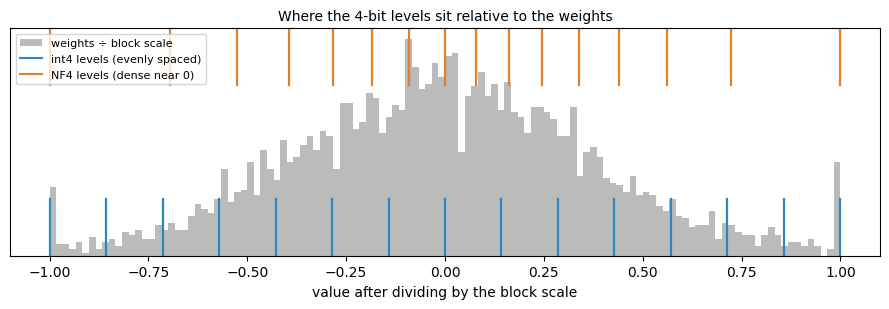

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
block = w[:4096].reshape(-1, 64)
normalized = (block / block.abs().amax(dim=1, keepdim=True)).flatten()
ax.hist(normalized, bins=120, color="#bbb", density=True, label="weights ÷ block scale")
for lv in INT4_LEVELS:
    ax.axvline(lv, ymin=0, ymax=0.25, color="#2e86c1", lw=1.6)
for lv in NF4_LEVELS:
    ax.axvline(lv, ymin=0.75, ymax=1.0, color="#e67e22", lw=1.6)
ax.plot([], [], color="#2e86c1", label="int4 levels (evenly spaced)")
ax.plot([], [], color="#e67e22", label="NF4 levels (dense near 0)")
ax.set_xlabel("value after dividing by the block scale"); ax.set_yticks([])
ax.set_title("Where the 4-bit levels sit relative to the weights", fontsize=10); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Reading the output**

- int8 has 255 levels, so its error is tiny. Most models lose little or no quality at 8 bits (Dettmers et al., 2022).
- With 4 bits there are only 15 or 16 levels, and *where you put them* matters. Most weights lie near zero, as the histogram shows. Evenly spaced int4 levels waste resolution on the rarely used tails.
- **NF4** ("4-bit NormalFloat", from the QLoRA paper) places its 16 levels where a bell-shaped distribution has its mass: dense near zero, sparse in the tails. On these weights its error is lower than evenly spaced int4 (about 0.09 against 0.11), for the same 4 bits.
- You do not need the derivation of NF4 to use it. The practical lesson is: **for 4-bit QLoRA, use `nf4`** (the alternative in `bitsandbytes` is `fp4`).

### Why blocks: outliers

Real LLM weights and activations contain a few **outliers**: values much larger than the rest (Dettmers et al., 2022). With one scale for a whole tensor, a single outlier sets the scale, and every other weight is squeezed into the few levels near zero. A scale per small block confines the damage to that block.

In [7]:
w_out = w.clone()
w_out[1000] = 1.0                                       # one outlier, 50 times the typical size

print(f"{'':<34}{'no outlier':>12}{'one outlier':>13}")
for label, block in [("one scale for the whole tensor", w.numel()), ("one scale per block of 64", 64)]:
    e1 = rel_error(w, quantize(w, NF4_LEVELS, block))
    e2 = rel_error(w_out, quantize(w_out, NF4_LEVELS, block))
    print(f"{label:<34}{e1:>12.4f}{e2:>13.4f}")

# the cost of the scales: one 32-bit scale per block, and QLoRA's "double quantization" of those scales
for block in (64, 256, 1024):
    print(f"block {block:>4}: scales add {32 / block:.3f} bits per weight")
print(f"block   64 with double quantization: {8 / 64 + 32 / (64 * 256):.3f} bits per weight (QLoRA paper)")

                                    no outlier  one outlier
one scale for the whole tensor          0.1238       0.9285
one scale per block of 64               0.0920       0.0945
block   64: scales add 0.500 bits per weight
block  256: scales add 0.125 bits per weight
block 1024: scales add 0.031 bits per weight
block   64 with double quantization: 0.127 bits per weight (QLoRA paper)


**Reading the output**

- With one scale for the whole tensor, the single outlier raises the error from about 0.12 to about 0.93. Divided by the outlier's size, a typical weight becomes about 0.02, and the nearest NF4 level is 0: almost every other weight is rounded to zero.
- With a scale per block of 64, only the outlier's own block suffers, and the overall error barely moves.
- **The price of blocks:** each block stores its own 32-bit scale, which adds 32 ÷ 64 = **0.5 bits per weight** at block size 64. A "4-bit" format then really costs 4.5 bits per weight.
- **Double quantization** shrinks that overhead by quantizing the scales too, in two levels:
  1. *First quantization:* the weights become 4-bit codes, with one scale per block of 64 weights.
  2. *Second quantization:* those scales are themselves stored as 8-bit codes. They are grouped 256 at a time, and each group of 256 scales shares one new 32-bit scale.

  The overhead per weight is then 8 ÷ 64 (an 8-bit scale shared by 64 weights) + 32 ÷ (64 × 256) (a 32-bit second-level scale shared by 64 × 256 weights) = 0.125 + 0.002 ≈ **0.127 bits per weight**, instead of 0.5. This is the last line printed above, and it is the `NF4_BYTES` figure we used in Section 1.
- `bitsandbytes` handles all of this for you. The settings you choose are the data type (`nf4`), double quantization (on or off), and the **compute dtype** (Section 4).

## 3. Which format for which job

"Quantized model" can mean several different things. They differ in **when** the quantization happens and **what software** runs the result.

| Your job | Typical choice | When it is quantized | Runs with |
| --- | --- | --- | --- |
| Fine-tune a model that is too big for your GPU | **`bitsandbytes` NF4 + LoRA = QLoRA** | when you load the model | `transformers` + `peft` |
| Save memory quickly, no fine-tuning | `bitsandbytes` 8-bit (LLM.int8) or 4-bit | when you load the model | `transformers` |
| Serve a model on GPUs at high throughput | **GPTQ** or **AWQ** checkpoints | once, ahead of time, using a small **calibration** dataset | vLLM, TGI, `transformers` |
| Run on a laptop or CPU | **GGUF** (llama.cpp formats) | once, ahead of time | llama.cpp, Ollama, LM Studio |

- A **checkpoint** is a saved copy of a model's weights (plus its configuration), the files you download from the Hugging Face Hub. The same model can be published as several checkpoints, such as a 16-bit one and quantized ones.
- **Load-time quantization** (`bitsandbytes`) needs no preparation: you download the normal 16-bit checkpoint and it is quantized as it loads. It is the most flexible choice, and the one QLoRA uses.
- **Pre-quantized checkpoints** (GPTQ, AWQ, GGUF) are prepared once, by whoever publishes them. You download a file that is already 4-bit. The result is a smaller download, and often faster inference with dedicated kernels. You generally do not fine-tune these files directly. The three differ in how they were made and where they run:
  - **GPTQ** and **AWQ** are made for GPU serving. Both run the model on some calibration text and choose the rounding to minimize the change in the model's *outputs* on that data, not just the error of each weight (Frantar et al., 2022; Lin et al., 2023). **GPTQ** rounds a layer's weights one at a time and adjusts the not-yet-rounded weights to compensate for each rounding error. **AWQ** (Activation-aware Weight Quantization) finds the small share of weights that matter most, judged by how large the activations passing through them are, and scales them up before rounding so that they lose less precision.
  - **GGUF** is the file format used by llama.cpp, Ollama and LM Studio. One `.gguf` file holds the quantized weights together with the tokenizer and model settings, so it can be run on its own, typically on a laptop CPU (with optional offloading of some layers to a GPU). It comes in many quantization levels, such as `q8_0` and `q4_k_m` (see the names below), so you can trade file size and memory against quality.

### Reading names on the Hub

Many model families publish several quantized versions. For Qwen2.5-1.5B-Instruct (file sizes checked on the Hub):

| Repository or file | Format | Size |
| --- | --- | ---: |
| `Qwen2.5-1.5B-Instruct` | original, bf16 | 3.09 GB |
| `Qwen2.5-1.5B-Instruct-GPTQ-Int4` | GPTQ, 4-bit | 1.15 GB |
| `Qwen2.5-1.5B-Instruct-AWQ` | AWQ, 4-bit | 1.61 GB |
| `Qwen2.5-1.5B-Instruct-GGUF` → `…-q8_0.gguf` | GGUF, 8-bit | 1.89 GB |
| `Qwen2.5-1.5B-Instruct-GGUF` → `…-q4_k_m.gguf` | GGUF, about 4-bit, mixed | 1.12 GB |
| `Qwen2.5-1.5B-Instruct-GGUF` → `…-q2_k.gguf` | GGUF, about 2-bit, mixed | 0.75 GB |

- In GGUF names, the number is the approximate bits per weight. `K` marks the "k-quant" family, and `S`/`M`/`L` say how many layers are kept at higher precision (small, medium, large). `q4_k_m` is a common default.
- **The AWQ file is larger than the GPTQ file** although both are 4-bit. Reading the file headers shows why: the AWQ file stores a separate 16-bit copy of the output head (467 MB) next to the embedding table, while the GPTQ file stores the shared table once. Packaging choices matter, so check the real file size.
- **Below 4 bits, quality usually drops noticeably**, especially for small models. Treat 2- and 3-bit files as a last resort, and test them.

## 4. QLoRA: a 4-bit frozen base with 16-bit adapters

QLoRA (Dettmers et al., 2023) is LoRA with one change: the frozen base weights are stored in **4-bit NF4** instead of 16-bit.

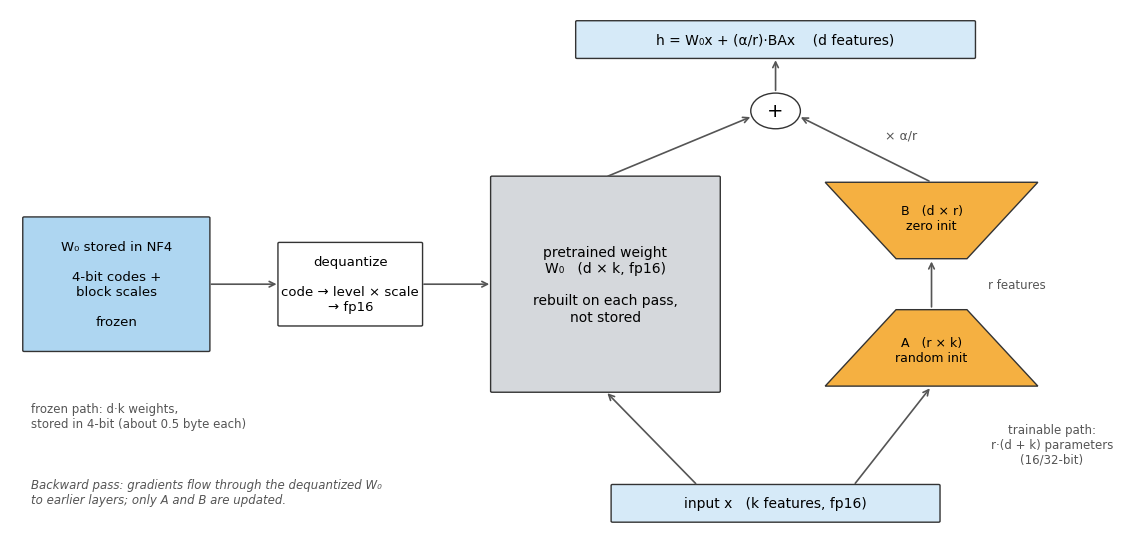

In [4]:
def draw_qlora():
    fig, ax = plt.subplots(figsize=(11.5, 5.6))
    ax.set_xlim(-5.8, 10); ax.set_ylim(0, 10.4); ax.axis("off")

    def box(x, y, w, h, label, color, fontsize=10):
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02", fc=color, ec="#333", lw=1))
        ax.text(x, y, label, ha="center", va="center", fontsize=fontsize)

    def arrow(start, end):
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="#555", lw=1.2))

    box(5, 0.7, 4.6, 0.7, "input x   (k features, fp16)", "#d6eaf8", 10)
    # frozen base weight: stored in NF4, dequantized to fp16 W0 on every pass
    box(-4.3, 5.0, 2.6, 2.6, "W₀ stored in NF4\n\n4-bit codes +\nblock scales\n\nfrozen", QUANT, 9.5)
    box(-1.0, 5.0, 2.0, 1.6, "dequantize\n\ncode → level × scale\n→ fp16", "white", 9.5)
    box(2.6, 5.0, 3.2, 4.2, "pretrained weight\nW₀   (d × k, fp16)\n\nrebuilt on each pass,\nnot stored", FROZEN, 10)
    arrow((-3.0, 5.0), (-2.0, 5.0)); arrow((0.0, 5.0), (1.0, 5.0))
    # LoRA path: unchanged from Lecture 1
    ax.add_patch(Polygon([[5.7, 3.0], [8.7, 3.0], [7.7, 4.5], [6.7, 4.5]], fc=TRAINABLE, ec="#333"))   # A: k -> r
    ax.text(7.2, 3.7, "A   (r × k)\nrandom init", ha="center", va="center", fontsize=9)
    ax.text(8.0, 5.0, "r features", ha="left", va="center", fontsize=8.5, color="#555")
    ax.add_patch(Polygon([[6.7, 5.5], [7.7, 5.5], [8.7, 7.0], [5.7, 7.0]], fc=TRAINABLE, ec="#333"))   # B: r -> d
    ax.text(7.2, 6.3, "B   (d × r)\nzero init", ha="center", va="center", fontsize=9)
    ax.add_patch(Circle((5, 8.4), 0.35, fc="white", ec="#333")); ax.text(5, 8.4, "+", ha="center", va="center", fontsize=14)
    box(5, 9.8, 5.6, 0.7, "h = W₀x + (α/r)·BAx    (d features)", "#d6eaf8", 10)
    arrow((3.9, 1.05), (2.6, 2.9)); arrow((6.1, 1.05), (7.2, 3.0))
    arrow((7.2, 4.5), (7.2, 5.5))
    arrow((2.6, 7.1), (4.68, 8.3)); arrow((7.2, 7.0), (5.32, 8.3))
    ax.text(6.55, 7.85, "× α/r", fontsize=9, color="#555")
    arrow((5, 8.75), (5, 9.45))
    ax.text(-5.5, 2.2, "frozen path: d·k weights,\nstored in 4-bit (about 0.5 byte each)", fontsize=8.5, color="#555")
    ax.text(8.9, 1.5, "trainable path:\nr·(d + k) parameters\n(16/32-bit)", fontsize=8.5, color="#555", ha="center")
    ax.text(-5.5, 0.7, "Backward pass: gradients flow through the dequantized W₀\nto earlier layers; only A and B are updated.",
            fontsize=8.5, style="italic", color="#555")
    plt.tight_layout(); plt.show()


draw_qlora()

**Reading the figure**

- The figure is Lecture 1's LoRA figure with two boxes added on the left. The frozen pretrained weight `W₀` is **stored** as NF4 (4-bit codes plus block scales). Just before it is used, the **dequantize** box turns each code back into `level × scale` in fp16, which gives the `W₀` box that the rest of the figure treats exactly as in LoRA. That fp16 `W₀` is rebuilt on every forward and backward pass and not kept.
- In other words, `W₀` is **stored** in 4-bit and **computed** in 16-bit. The QLoRA paper calls these the *storage* data type (NF4) and the *compute* data type (bf16 in the paper; fp16 on a T4).
- The adapter path is exactly Lecture 1's LoRA. Only `A` and `B` receive weight gradients, so the optimizer state is tiny.
- Gradients still have to pass **through** the frozen 4-bit layers on their way to earlier adapters. The 4-bit weights are never updated, so their rounding error does not grow during training.

### The three ingredients of the QLoRA paper

| Ingredient | What it does | Setting in Hugging Face |
| --- | --- | --- |
| **NF4** | 4-bit levels placed for bell-shaped weights (Section 2) | `bnb_4bit_quant_type="nf4"` |
| **Double quantization** | stores the block scales in 8-bit: about 0.37 bits per weight saved, about 3 GB for a 65B model | `bnb_4bit_use_double_quant=True` |
| **Paged optimizers** | moves optimizer state to CPU memory during sudden memory spikes, instead of crashing | `optim="paged_adamw_8bit"` (or `paged_adamw_32bit`) in `TrainingArguments` |

### What the paper showed, and what it recommends

- **Scale.** QLoRA fine-tuned a 65B model on a single 48 GB GPU, where 16-bit full fine-tuning needs more than 780 GB.
- **Quality.** In the paper's experiments, NF4 QLoRA matched 16-bit full fine-tuning and 16-bit LoRA on the benchmarks tested. This is an empirical result for those models and tasks, not a guarantee: always compare on your own task.
- **Put adapters on all linear layers.** The paper found that LoRA on only the query and value projections did not match full fine-tuning, and that adapting **all linear layers** was the most important setting. The rank `r` mattered much less.
- **Activations dominate.** For a 7B model the paper reports 5,048 MB for the 4-bit base, but only 26 MB for the LoRA weights. Without gradient checkpointing, the activation gradients flowing into the adapters took 567 MB per sequence. **Gradient checkpointing** (recompute activations in the backward pass instead of storing them) is therefore part of the standard recipe.

### The recipe in code

```python
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,                      # quantize the linear layers as they load
    bnb_4bit_quant_type="nf4",              # NF4 levels
    bnb_4bit_use_double_quant=True,         # 8-bit block scales
    bnb_4bit_compute_dtype=torch.float16,   # T4: fp16. bf16 on Ampere or newer GPUs (A100, L4, RTX 30xx+)
)
model = AutoModelForCausalLM.from_pretrained(
    checkpoint, 
    quantization_config=bnb_config,
    dtype=torch.float16, device_map={"": 0}
)

model = prepare_model_for_kbit_training(          # freeze, upcast norms/embeddings to fp32, enable checkpointing
    model, 
    gradient_checkpointing_kwargs={"use_reentrant": False}
)   # the variant PyTorch recommends

model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                                         target_modules="all-linear", task_type="CAUSAL_LM"))
# then train with Trainer as usual, e.g. TrainingArguments(..., fp16=True, optim="paged_adamw_8bit")
```

- **`prepare_model_for_kbit_training`** freezes every base parameter, casts the remaining 16-bit parameters (norms, embeddings, output head) to fp32 for stability, makes the input embeddings pass gradients along, and turns on gradient checkpointing.
- **`target_modules="all-linear"`** asks `peft` to wrap every linear layer except the output head, following the paper's advice.
- **The compute dtype must match the hardware.** bf16 needs an NVIDIA Ampere GPU or newer. A T4 (Turing) has no bf16 support, so use fp16 there, and train with `fp16=True`.
- **`device_map={"": 0}`** puts the whole model on GPU 0. On Kaggle's "T4 ×2" machines, `device_map="auto"` would split the model across both GPUs, which works for inference but complicates training.

## 5. After training: save, merge, deploy

Training produces a LoRA **adapter**, a few tens of MB, exactly as in Lecture 1. What you do next depends on how the model will be used.

| Option | How | When to choose it |
| --- | --- | --- |
| **Keep the adapter separate** | ship the adapter; load the base in 4-bit or 16-bit, then `PeftModel.from_pretrained(base, adapter_dir)` | several tasks share one base; you want to switch adapters; storage matters |
| **Merge into a 16-bit base** | reload the base **in fp16/bf16** (not 4-bit), load the adapter, `merge_and_unload()`, `save_pretrained()` | you want one ordinary model file, e.g. for a serving engine |
| **Merge, then quantize for serving** | merge as above, then convert the merged model to GPTQ, AWQ, or GGUF | deployment on limited hardware |

**Why not merge into the 4-bit weights?** The merged weight `W + (α/r)·BA` would have to be rounded back to 4 bits, and the small learned update can be partly lost in that rounding. `peft` allows it but warns that the results may differ. The clean route is to merge into a 16-bit copy of the base, then quantize again if you need a small file.

**Train and serve with the same base.** The adapter was trained against the *4-bit* base. Running it on the 16-bit base usually works well, because the two bases are very close, but it is not identical. Evaluate the model in the form you will deploy it.

## 6. A decision checklist and common pitfalls

**Choosing an approach**

```text
Will the 16-bit model + LoRA fit on your GPU (Section 1 arithmetic, then measure)?
 ├─ yes → plain LoRA in 16-bit: simpler and usually faster than QLoRA
 └─ no  → QLoRA (NF4, double quantization, fp16/bf16 compute, all-linear adapters, gradient checkpointing)

Only running the model, not training it?
 ├─ GPU server, many users     → GPTQ or AWQ checkpoint, served with vLLM or TGI
 ├─ laptop or CPU              → GGUF (q4_k_m is a common start), with llama.cpp or Ollama
 └─ quick experiment in Python → bitsandbytes 8-bit or 4-bit at load time
```

**Common pitfalls**

| Pitfall | What happens | What to do instead |
| --- | --- | --- |
| Expecting quantization to make things faster | load-time 4-bit is often slower than 16-bit | quantize to save memory; measure speed separately |
| bf16 compute dtype on a T4 | errors or very slow emulation | use `torch.float16` and `fp16=True` on Turing GPUs |
| Comparing models under different conditions | differences come from prompts or decoding, not quantization | same prompts, same decoding settings, same evaluation set |
| Merging into the 4-bit weights | the update is partly lost to rounding | merge into a 16-bit copy of the base |
| Trusting "4-bit is as good as 16-bit" | quality loss depends on model size, task, and format | evaluate the quantized model on your task |
| Forgetting activations and the KV cache | out-of-memory with long sequences or big batches | gradient checkpointing, shorter sequences, smaller batches; measure peak memory |
| Library version clashes | import errors in `bitsandbytes`, `peft`, or `torchao` | note the working versions; on Kaggle see the `torchao` fix in Lecture 1 |

**What quantization does not change:** the model's behavior is still that of the original model, plus a small error. A quantized model that hallucinates did not start hallucinating because of quantization, and quantization will not fix it. Evaluate the base, the quantized base, and the fine-tuned model on the same examples to see which step changed what.

## 7. Optional: measure it on a real model

> **This section downloads a model.** Set `RUN_QUANT_DEMO = True` to run it.
> - [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): about 3.1 GB, Apache-2.0 license.
> - Needs a **GPU (Kaggle T4)**, **internet on**, and the `bitsandbytes` package (install cell below). Uses `transformers` and `peft`.
> - Writes nothing to disk except the Hugging Face cache. Nothing is trained: Part C runs one backward pass to measure memory.
> - The cells load the model twice (16-bit, then 4-bit) and free the first copy in between.

The demo checks the claims of Sections 1–4 on a real model: memory, speed, output, and what a quantized layer looks like inside.

In [9]:
# Setup for Section 7 only. Run once per session on Kaggle, then restart the kernel if pip upgraded a loaded package.
# %pip install -q -U bitsandbytes
# If get_peft_model later raises "Found an incompatible version of torchao", also run the line below and restart:
# %pip uninstall -y torchao

In [10]:
RUN_QUANT_DEMO = True          # True: download Qwen2.5-1.5B-Instruct (~3.1 GB) and measure it in 16-bit and 4-bit

if RUN_QUANT_DEMO:
    import gc
    import time

    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

    CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(CKPT)
    messages = [{"role": "user", "content": "Explain in two sentences why a GPU has limited memory for large models."}]
    prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    batch = tokenizer(prompt, return_tensors="pt").to("cuda")

    def measure(model, label, new_tokens=64):
        """Memory held by the weights, greedy generation speed, and the generated text."""
        weights_gb = torch.cuda.memory_allocated() / GB
        model.generate(**batch, max_new_tokens=4, do_sample=False)            # warm-up
        torch.cuda.synchronize(); start = time.perf_counter()
        out = model.generate(**batch, max_new_tokens=new_tokens, min_new_tokens=new_tokens, do_sample=False)
        torch.cuda.synchronize(); seconds = time.perf_counter() - start
        text = tokenizer.decode(out[0, batch["input_ids"].shape[1]:], skip_special_tokens=True)
        print(f"{label}: weights on GPU {weights_gb:.2f} GB | {new_tokens / seconds:.1f} tokens/s")
        print("   ", text[:300].replace("\n", " "), "\n")
        return weights_gb, new_tokens / seconds

    def free(model):
        del model; gc.collect(); torch.cuda.empty_cache()

    # A. 16-bit (T4: fp16, since it has no bf16 support)
    torch.cuda.empty_cache()
    model16 = AutoModelForCausalLM.from_pretrained(CKPT, dtype=torch.float16, device_map={"": 0})
    results = {"fp16": measure(model16, "fp16")}
    free(model16); model16 = None

    # B. 4-bit NF4 with double quantization, fp16 compute
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                    bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
    model4 = AutoModelForCausalLM.from_pretrained(CKPT, quantization_config=bnb_config,
                                                  dtype=torch.float16, device_map={"": 0})
    results["nf4"] = measure(model4, "NF4")
    print(f"Section 1 estimate for 4-bit: {budget(QWEN['Qwen2.5-1.5B'])['infer 4-bit'] / GB:.2f} GB")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


fp16: weights on GPU 3.09 GB | 25.0 tokens/s
    A GPU has limited memory because it is designed to handle multiple tasks simultaneously and efficiently manage the processing of data streams, which requires allocating resources based on the specific needs of each task rather than having unlimited storage capacity. Additionally, GPUs are optimized  



Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

NF4: weights on GPU 1.16 GB | 18.7 tokens/s
    A Graphics Processing Unit (GPU) is designed to handle parallel processing tasks efficiently but does not have the same level of memory capacity as a Central Processing Unit (CPU). This limitation means that GPUs can struggle with running very large or complex machine learning models due to insuffic 

Section 1 estimate for 4-bit: 1.14 GB


**Reading the output** (our run: Kaggle T4, PyTorch 2.10, `transformers` 5.0)

| | fp16 | NF4 | Section 1 estimate |
| --- | ---: | ---: | ---: |
| GPU memory for the weights | 3.09 GB | 1.16 GB | 3.09 GB / 1.14 GB |
| Greedy generation speed | 25.0 tokens/s | 18.7 tokens/s | — |

- **Memory:** NF4 holds 38% of the fp16 memory, within 0.02 GB of the estimate. Not a quarter, because the embedding table stays 16-bit.
- **Speed:** NF4 was about 25% **slower**. Every layer dequantizes its weights on each step (Section 2). Quantization bought memory, not time.
- **Output:** greedy decoding is deterministic, so the difference between the two texts comes from quantization alone. The wording changed completely from the first sentence on. Note also that **neither** answer is good: the fp16 model claims GPU memory is limited "because it is designed to handle multiple tasks simultaneously", which is wrong, and the NF4 model makes a loose comparison with CPU memory. Quantization changes the details; it neither causes nor fixes the weaknesses of a small model. Judging quality needs an evaluation on many examples, as in the lab.
- The warning about `temperature`, `top_p`, and `top_k` comes from the model's default sampling settings, which greedy decoding ignores. It is harmless.

In [11]:
if RUN_QUANT_DEMO:
    layer = model4.model.layers[0].mlp.down_proj
    print(type(layer).__module__ + "." + type(layer).__name__)
    print("stored weight:", layer.weight.dtype, tuple(layer.weight.shape), "| original shape (out, in):",
          (layer.out_features, layer.in_features))
    qs = layer.weight.quant_state
    print("quant type:", qs.quant_type, "| block size:", qs.blocksize, "| double-quantized scales:", qs.nested)
    print("embedding table dtype:", model4.model.embed_tokens.weight.dtype, "(not quantized)")

bitsandbytes.nn.modules.Linear4bit
stored weight: torch.uint8 (6881280, 1) | original shape (out, in): (1536, 8960)
quant type: nf4 | block size: 64 | double-quantized scales: True
embedding table dtype: torch.float16 (not quantized)


**Reading the output**

- The linear layer is now a `bitsandbytes` `Linear4bit`. Its weight is stored as a `uint8` column of 6,881,280 entries: exactly half of the 1536 × 8960 = 13,762,560 weights, because two 4-bit codes are packed into each byte.
- The quantization state records the settings from `BitsAndBytesConfig`: NF4, blocks of 64, and nested (double-quantized) scales.
- The embedding table is still 16-bit, as Section 1 assumed.

In [12]:
if RUN_QUANT_DEMO:
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

    model4 = prepare_model_for_kbit_training(model4)
    model4 = get_peft_model(model4, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                                               target_modules="all-linear", task_type="CAUSAL_LM"))
    model4.print_trainable_parameters()
    print(f"Section 1 formula: {lora_params(QWEN['Qwen2.5-1.5B'], 16):,} adapter parameters")

    # One training step's worth of memory: forward + backward on a 512-token batch of 4
    model4.train()
    ids = torch.randint(0, 150000, (4, 512), device="cuda")
    torch.cuda.reset_peak_memory_stats()
    model4(input_ids=ids, labels=ids).loss.backward()
    print(f"peak memory for one forward + backward pass: {torch.cuda.max_memory_allocated() / GB:.2f} GB"
          f" (Section 1 estimate before activations: {budget(QWEN['Qwen2.5-1.5B'])['QLoRA'] / GB:.2f} GB)")

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
Section 1 formula: 18,464,768 adapter parameters


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1181: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


peak memory for one forward + backward pass: 5.80 GB (Section 1 estimate before activations: 1.91 GB)


**Reading the output**

- `peft` reported 18,464,768 trainable parameters: exactly the Section 1 formula for all linear layers at `r = 16`. Its "all params" figure, 1,562,179,072, is the base model's 1,543,714,304 plus the adapter (it counts each packed 4-bit weight at its original size).
- The peak memory was **5.80 GB**, three times the 1.91 GB estimate. The estimate leaves out everything that depends on the batch. A rough accounting points to the **output logits** as the largest part: 4 × 512 tokens × 151,936 vocabulary entries is 311M scores, or 1.24 GB per copy in fp32 (the output head was upcast to fp32), and computing the loss and its gradient keeps more than one such copy. The checkpointed activations of the 28 layers are much smaller (about 0.2 GB in fp16).
- **Practical lesson:** for models with large vocabularies, batch size × sequence length drives memory through the logits. Halving either one roughly halves this part. Rerun the cell with a batch of 1 to see it.
- The `use_reentrant` warning comes from PyTorch's gradient checkpointing. Passing `gradient_checkpointing_kwargs={"use_reentrant": False}` to `prepare_model_for_kbit_training`, as in Section 4 and the lab, selects the recommended variant and silences it.
- The [QLoRA lab](../../labs/qlora_dialogsum/qlora_dialogsum_lab.ipynb) takes this setup through real training and evaluation.

## 8. Summary

| Idea | What it means in practice | Section |
| --- | --- | --- |
| Memory budget | parameters × bytes per parameter, plus activations, logits, and KV cache; estimate, then measure | 1, 7 |
| Not everything is quantized | embeddings and the output head usually stay 16-bit, so 4-bit ≠ ¼ of the size | 1, 3 |
| Quantization | small integer codes + a scale per block; dequantized to 16-bit for every computation | 2 |
| Memory, not speed | load-time 4-bit saves memory and is often slower (25% slower in our T4 run) | 2, 7 |
| NF4 | 4-bit levels placed where weights are dense; the standard choice for QLoRA | 2 |
| Blocks | limit the damage of outliers; double quantization shrinks the scale overhead | 2 |
| Formats | `bitsandbytes` for fine-tuning; GPTQ/AWQ for GPU serving; GGUF for laptops/CPU | 3 |
| QLoRA | frozen NF4 base + LoRA on all linear layers + gradient checkpointing (+ paged optimizer) | 4 |
| Compute dtype | fp16 on a T4, bf16 on Ampere or newer | 4 |
| After training | keep the adapter, or merge into a **16-bit** base and quantize again for serving | 5 |
| Always evaluate | quality loss depends on the model, task, and format | 6 |

## 9. Check your understanding

1. Qwen2.5-1.5B has 1.54B parameters. Why is its 4-bit checkpoint about 1.1 GB rather than 0.77 GB?
2. A colleague quantizes a model to 4-bit with `bitsandbytes` and expects generation to become four times faster. What do you tell them?
3. Why does one outlier hurt much more when a whole tensor shares one scale than when every block of 64 weights has its own?
4. You have a 16 GB T4. Which approach would you choose to fine-tune (a) Qwen2.5-1.5B and (b) Qwen2.5-7B? Justify each with the Section 1 arithmetic.
5. In QLoRA, which parameters are stored in 4-bit, which are trained, and in which dtype does the matrix multiplication run on a T4?
6. Why does the QLoRA recipe use gradient checkpointing, even though the adapters themselves are tiny?
7. You need to serve a fine-tuned model to many users on a GPU server, and also offer an offline version for laptops. Describe the steps from your QLoRA adapter to each deployment.
8. Why is merging a LoRA adapter directly into 4-bit weights discouraged?

<details>
<summary><b>Show answers</b></summary>

1. Only the decoder's linear layers (1.31B parameters) are quantized. The 233M-parameter embedding table stays 16-bit (about 0.47 GB), and the block scales add a little more.
2. Load-time 4-bit quantization saves memory, not time. The weights are dequantized to 16-bit for every computation, so generation is usually no faster and often slower (in Section 7, NF4 was about 25% slower than fp16 on a T4). Speed-ups need formats with dedicated kernels (e.g. GPTQ/AWQ with a serving engine), and must be measured.
3. The outlier sets the scale. With one scale, every weight in the tensor is divided by the outlier's size and squeezed into the few levels near zero. With blocks, only the 63 other weights in the outlier's block are affected.
4. (a) LoRA in 16-bit already fits (about 3.4 GB before activations), and is simpler; QLoRA also works. (b) LoRA needs about 16 GB before activations, which does not fit; QLoRA needs about 8 GB, leaving room for activations.
5. The base model's decoder linear layers are stored in 4-bit NF4. Only the LoRA matrices `A` and `B` are trained. On a T4, the computation runs in fp16 (bf16 is not supported).
6. Most training memory goes to activations, not to the adapters. The backward pass must run through every layer to reach the earliest adapters, so activations are stored for all layers unless they are recomputed. The QLoRA paper measured 567 MB of activation gradients per sequence for a 7B model, against 26 MB of LoRA weights.
7. Load the 16-bit base, load the adapter, `merge_and_unload()`, and save a 16-bit model. For the server, quantize that model to GPTQ or AWQ and serve it with vLLM or TGI (or serve the 16-bit model if memory allows). For laptops, convert the merged model to GGUF (for example `q4_k_m`) and run it with llama.cpp or Ollama. Evaluate each deployed form.
8. The merged weight has to be rounded back to 4 bits, and the small learned update can be partly lost in that rounding. Merge into a 16-bit copy of the base instead.

</details>

## References

1. Dettmers, Pagnoni, Holtzman & Zettlemoyer, [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
2. Dettmers, Lewis, Belkada & Zettlemoyer, [LLM.int8(): 8-bit Matrix Multiplication for Transformers at Scale](https://arxiv.org/abs/2208.07339), 2022.
3. Frantar, Ashkboos, Hoefler & Alistarh, [GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers](https://arxiv.org/abs/2210.17323), 2022.
4. Lin et al., [AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration](https://arxiv.org/abs/2306.00978), 2023.
5. Hugging Face documentation: [bitsandbytes quantization in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT quantization guide](https://huggingface.co/docs/peft/developer_guides/quantization) · [GGUF on the Hub](https://huggingface.co/docs/hub/gguf).
6. [bitsandbytes](https://github.com/bitsandbytes-foundation/bitsandbytes) (the NF4 levels in Section 2 are taken from its source) · [llama.cpp](https://github.com/ggml-org/llama.cpp).
7. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024 · [Qwen2.5-1.5B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct).